![Banner](../images/09_11_banner_rs_foundation_models.png)


# Geospatial foundation models: embeddings, promptable segmentation and zero-shot classification

A foundation model is a large network pretrained once, on a very large and varied archive, and then reused for many tasks with little or no new training.


## Overview

For remote sensing this means encoders such as NASA/IBM **Prithvi-EO-2.0** or **DOFA** that turn a Sentinel-2 or Landsat patch into a feature vector, **Segment Anything (SAM)** that cuts an image into objects from a point or a box, and vision-language models such as **RemoteCLIP** that match an image to a sentence. They promise maps with few or no labels. They also produce confident output for inputs they were never meant for, so every result in this notebook is scored against reference labels before it is believed.

The notebook uses three datasets that are already on the local drive:

- **`Corn_belt` Sentinel-2**: the 26 August 2025 Sentinel-2 L2A scene over the Iowa corn belt study area (30 km × 29 km, 10 bands), with the 2025 USDA Cropland Data Layer (CDL) as reference. Used for foundation-model embeddings, similarity search and few-shot crop classification.
- **`Sentinel_2_UB`**: a small 10-band Sentinel-2 image of the University at Buffalo North Campus (1.7 km × 2.1 km) with labelled points of five land-use classes. Used for few-shot classification at the pixel level.
- **`Landcover_data`**: the DeepGlobe 2018 land-cover tiles (RGB, 50 cm, 2,448 × 2,448 pixels) with reference masks of six classes. Used for SAM, text-prompted segmentation and zero-shot classification.

**A GPU is recommended and the weights are downloaded on first use** (about 7 GB in total: DOFA 0.4 GB, Prithvi-EO-2.0-300M 1.3 GB, SAM ViT-H 2.6 GB, Grounding DINO 0.7 GB, RemoteCLIP and GeoRSCLIP 0.6 GB each). They are cached by PyTorch and Hugging Face, so later runs read them from the local drive.


## Core concepts

### Learning objectives

1. List the geospatial foundation models in GeoLattice and read each model's licence from its model card.
2. Load DOFA and Prithvi-EO-2.0 and write a TerraTorch fine-tuning configuration.
3. Embed corn-belt patches, find similar places, and classify crops from five labels per class.
4. Repeat the few-shot test on the University at Buffalo campus points.
5. Segment DeepGlobe objects from points, boxes and words.
6. Classify DeepGlobe crops with RemoteCLIP and GeoRSCLIP, and measure how prompt wording changes the result.
7. Score every output before use and write the few-shot crop map with its provenance.

### Contents

1. Workflow and GeoLattice functions
2. Model zoo
3. Load foundation encoders
4. Embeddings as features
5. Promptable segmentation
6. Zero-shot classification
7. Trust: score every output before use
8. Interpretation and limitations


## Workflow and GeoLattice functions

1. Model zoo: list the geospatial foundation models with `foundation_model_info`, and read each model's licence from its model card.
2. Load encoders with `load_foundation_encoder` (DOFA and Prithvi-EO-2.0), and write a fine-tuning configuration with `terratorch_config`.
3. Embeddings as features: embed every 160 m patch of the corn belt scene, find similar places with `embedding_search`, and classify crops from five labels per class with `few_shot_prototypes`; repeat the few-shot test on the UB campus points.
4. Promptable segmentation: segment DeepGlobe objects from points and boxes with `sam_segment`, and from words with `text_prompt_segment`.
5. Zero-shot classification: load RemoteCLIP and GeoRSCLIP with `load_rs_clip`, classify DeepGlobe crops with `zero_shot_classify`, and measure how much the prompt wording changes the result.
6. Trust: every function above returns `verified=False` and the `UNVERIFIED_NOTE`; collect all scores in one table and write the few-shot crop map with that provenance.

The functions live in `geolattice.rsense.classify.image_classification` (imported as `ic`). The optional packages are `torchgeo` (DOFA), `terratorch` (Prithvi), `segment-geospatial` with `groundingdino-py` (SAM and text prompts) and `open_clip_torch` (RemoteCLIP).


### Imports, paths, and settings

This cell imports the libraries, finds the repository, checks that the three datasets are on the local drive, and picks the GPU when one is available. `USE_TF=0` stops the `transformers` library (used by Grounding DINO) from also loading TensorFlow. `TILE` is the input size of the ViT encoders (224 pixels) and `PATCH` their patch size (16 pixels): every 224 × 224 tile becomes a 14 × 14 grid of patch embeddings.


**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `huggingface_hub`, `geolattice[rsense-foundation]`, `pyyaml`, which no GeoLattice option installs: `pip install huggingface_hub "geolattice[rsense-foundation]" pyyaml`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import sys  # Python import path
import time  # timing
import warnings  # warning control
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rasterio  # raster reading and writing
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: all models run on it
import yaml  # write the TerraTorch configuration
from matplotlib.colors import ListedColormap  # class colours
from PIL import Image  # read the DeepGlobe JPEG and PNG files
from rasterio.transform import Affine  # pixel-unit transform for the DeepGlobe tiles
from scipy import ndimage  # connected components and distances

warnings.filterwarnings("ignore")  # hide library warnings

# Prefer this checkout's code when launched from the repository.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").exists() and (p / "src" / "rsense").is_dir()), None)
if ROOT is not None:  # a checkout was found
    sys.path.insert(0, str(ROOT / "src"))  # import GeoLattice from its src folder

import geolattice.rsense as rs  # GeoLattice remote sensing (raster reading and writing)
import geolattice.rsense.classify.image_classification as ic  # foundation-model tools

if ROOT is None:  # not started inside the repository
    raise FileNotFoundError("Start Jupyter from the GeoLattice checkout or one of its subdirectories")  # stop
# this notebook's folder
NOTEBOOK_DIR = ROOT / "Tutorials" / "notebooks" / "08_remote_sensing" / "09_11_foundations_models"
# data folder shared with chapter 08_09
DATA_DIR = NOTEBOOK_DIR / "../../../../Data/08_remote_sensing/08_09_image_classification"
S2_SCENE = DATA_DIR / "Corn_belt" / "Sentinel_2" / "2025_08_20250826"  # corn belt Sentinel-2 scene
CDL_PATH = DATA_DIR / "Corn_belt" / "CDL" / "10_m" / "CDL_2025_10m.tif"  # CDL 2025 at 10 m
UB_DIR = DATA_DIR / "Sentinel_2_UB"  # UB North Campus image and points
LC_DIR = DATA_DIR / "Landcover_data"  # DeepGlobe land-cover tiles
OUTPUT_DIR = NOTEBOOK_DIR / "outputs" / "foundation_models"  # outputs of this notebook
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # create it if needed

missing = [str(p) for p in (S2_SCENE, CDL_PATH, UB_DIR, LC_DIR) if not p.exists()]  # inputs not found
if missing:  # stop early with the list of missing inputs
    raise FileNotFoundError("Missing on the local drive: " + ", ".join(missing))  # stop

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
if DEVICE == "cpu":  # everything still runs, only slower
    print("No GPU found: the models will run on the CPU and take much longer")  # warn
TILE, PATCH = 224, 16  # ViT input size and patch size (pixels)
SEED = 7  # random seed
rng = np.random.default_rng(SEED)  # random generator for sampling
torch.manual_seed(SEED)  # reproducible model randomness
print("GeoLattice checkout:", ROOT)  # repository path
# PyTorch version and GPU name
print("PyTorch:", torch.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu")
print("Output folder:", OUTPUT_DIR)  # output folder


GeoLattice checkout: /home/zia207/Github/GeoLattice
PyTorch: 2.14.0+cu132 | device: NVIDIA RTX A5500 Laptop GPU
Output folder: /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_09_image_classification/outputs/foundation_models


## Model zoo

### Geospatial foundation models in GeoLattice

`foundation_model_info` returns a table of the main geospatial foundation models: who released them, the architecture, the bands each one expects, whether it uses time series, where the weights are hosted, how GeoLattice loads them, and the preprocessing they assume. Three points decide whether a model fits a task:

- **Inputs.** Prithvi-EO-2.0 expects six Harmonized Landsat Sentinel-2 (HLS) bands at 30 m; SatMAE and SSL4EO-S12 expect Sentinel-2 bands; Scale-MAE expects RGB. DOFA and Clay are **wavelength-aware**: they take any set of bands, given each band's central wavelength, which is why DOFA is used for both Sentinel-2 and RGB below.
- **Preprocessing.** Each model was pretrained with a particular scaling (reflectance divided by 10,000, per-band mean and standard deviation, clipping). Feeding a different scaling silently shifts the features.
- **Licence.** The table says "check model card" on purpose: licences change between releases, so they are read from the model card itself in the next cell.


In [2]:
zoo = ic.foundation_model_info()  # one row per model
zoo[["provider", "architecture", "inputs", "temporal", "loader", "preprocessing"]]  # the main columns

,provider,architecture,inputs,temporal,loader,preprocessing
prithvi-eo-2.0,NASA / IBM,ViT MAE (3-D patch embedding),"HLS: blue, green, red, nir08, swir16, swir22",True,terratorch (BACKBONE_REGISTRY 'prithvi_eo_v2_3...,"HLS reflectance, dataset mean/std"
clay-v1.5,Clay Foundation,"ViT MAE, wavelength-aware patch embed",any sensor (band wavelengths supplied),via date metadata,claymodel / terratorch,per-sensor normalization from metadata
satlaspretrain,Allen Institute for AI,Swin-v2 + FPN,"Sentinel-2 RGB or 9-band, NAIP, Landsat, Senti...",multi-image,torchgeo Swin_V2_B_Weights / satlaspretrain,"reflectance / 3000 clipped to [0, 1]"
dofa,TUM / Zhu lab,ViT with dynamic wavelength-conditioned stem,any band set (wavelengths in µm),False,torchgeo dofa_base_patch16_224,per-band standardization
skysense,Ant Group / Wuhan University,multimodal factorized spatiotemporal encoder,"high-res optical, Sentinel-2 time series, Sent...",True,authors' code,per-modality
ssl4eo-s12,TUM,"ResNet / ViT (MoCo, DINO, MAE, data2vec)","Sentinel-2 13 bands, Sentinel-1 VV/VH",seasonal views,torchgeo / load_rs_backbone,reflectance / 10000
satmae,Stanford,ViT MAE with temporal/spectral encoding,fMoW RGB / Sentinel-2 10 bands,True,geolattice.rsense.dl.foundation.SatMAE,dataset mean/std
scale-mae,UC Berkeley,ViT MAE with GSD-aware positional encoding,RGB,False,timm-compatible ViT state dict,ImageNet mean/std


In [3]:
ic.foundation_model_info("prithvi-eo-2.0")  # all fields of one model

{'provider': 'NASA / IBM',
 'architecture': 'ViT MAE (3-D patch embedding)',
 'inputs': 'HLS: blue, green, red, nir08, swir16, swir22',
 'temporal': True,
 'hub': 'ibm-nasa-geospatial/Prithvi-EO-2.0-300M (also -600M, -TL variants)',
 'loader': "terratorch (BACKBONE_REGISTRY 'prithvi_eo_v2_300')",
 'license': 'check model card',
 'preprocessing': 'HLS reflectance, dataset mean/std'}

### Read the licences from the model cards

The licence of each model used in this notebook, and of a few others, is read from its Hugging Face model card with `huggingface_hub.model_info`. This is the licence the authors declared on the card at the time the notebook runs; the paper, the code repository and the training data can carry further terms. Apache-2.0 and CC-BY-4.0 both allow commercial use (CC-BY-4.0 requires attribution); a card with no licence, or a generic "cc", needs a closer look before the weights or their outputs are redistributed. This is not legal advice.


In [4]:
from huggingface_hub import model_info  # Hugging Face model-card metadata

CARDS = {  # model -> Hugging Face repository
    "Prithvi-EO-2.0-300M": "ibm-nasa-geospatial/Prithvi-EO-2.0-300M",
    "Clay v1.5": "made-with-clay/Clay",
    "DOFA": "earthflow/DOFA",
    "SatlasPretrain": "allenai/satlas-pretrain",
    "SAM 2 (Hiera-L)": "facebook/sam2-hiera-large",
    "Grounding DINO": "ShilongLiu/GroundingDINO",
    "RemoteCLIP": "chendelong/RemoteCLIP",
    "GeoRSCLIP": "Zilun/GeoRSCLIP",
}
rows = {}  # one row per model
for name, repo in CARDS.items():  # each model card
    try:
        info = model_info(repo)  # card metadata from the Hub
        card = info.card_data.to_dict() if info.card_data else {}  # the card's YAML header
        rows[name] = {"repository": repo, "licence on card": card.get("license") or "none stated",  # licence declared on the card
                      "last modified": f"{info.last_modified:%Y-%m-%d}" if info.last_modified else ""}
    except Exception as exc:  # offline or repository moved
        rows[name] = {"repository": repo, "licence on card": f"not checked ({type(exc).__name__})",  # record why it was not checked
                      "last modified": ""}
pd.DataFrame(rows).T  # show the table

,repository,licence on card,last modified
Prithvi-EO-2.0-300M,ibm-nasa-geospatial/Prithvi-EO-2.0-300M,apache-2.0,2025-10-09
Clay v1.5,made-with-clay/Clay,apache-2.0,2026-04-05
DOFA,earthflow/DOFA,cc-by-4.0,2025-06-10
SatlasPretrain,allenai/satlas-pretrain,apache-2.0,2024-05-09
SAM 2 (Hiera-L),facebook/sam2-hiera-large,apache-2.0,2025-08-15
Grounding DINO,ShilongLiu/GroundingDINO,apache-2.0,2023-04-11
RemoteCLIP,chendelong/RemoteCLIP,none stated,2023-07-27
GeoRSCLIP,Zilun/GeoRSCLIP,cc,2024-10-10


## Load foundation encoders

### DOFA: one encoder for any band set

`load_foundation_encoder("dofa")` loads DOFA ViT-Base (Xiong et al. 2024) through TorchGeo with its MAE-pretrained weights. DOFA's first layer is a **dynamic** patch embedding: a small hypernetwork turns the central wavelength of each input band into that band's convolution weights. The same network therefore accepts the ten Sentinel-2 bands used here, or the three DeepGlobe RGB bands, as long as the wavelengths (in micrometres) are passed with the image.

TorchGeo's `forward_features` averages the 196 patch tokens into one vector per image. For maps, the patch tokens themselves are more useful: `dofa_tokens` repeats the same steps but keeps the 14 × 14 grid of tokens, one 768-number embedding per 16 × 16 pixel patch.


In [5]:
WAVELENGTHS = {  # central wavelength of each Sentinel-2 band (micrometres)
    "blue": 0.490, "green": 0.560, "red": 0.665, "rededge1": 0.705, "rededge2": 0.740,
    "rededge3": 0.783, "nir": 0.842, "nir08": 0.865, "swir16": 1.610, "swir22": 2.190}
S2_BANDS = list(WAVELENGTHS)  # band order used throughout

t0 = time.time()  # start the timer
dofa = ic.load_foundation_encoder("dofa").to(DEVICE).eval()  # DOFA ViT-Base, MAE weights (downloaded once)
print(f"DOFA: {sum(p.numel() for p in dofa.parameters()) / 1e6:.0f} M parameters, loaded in {time.time() - t0:.0f} s")  # model size and load time


def dofa_tokens(x, wavelengths):  # patch embeddings (B, 196, 768) of a (B, C, 224, 224) batch
    with torch.no_grad():  # inference only
        waves = torch.tensor(wavelengths, device=x.device).float()  # wavelengths of the bands
        t, _ = dofa.patch_embed(x, waves)  # wavelength-conditioned patch embedding
        t = t + dofa.pos_embed[:, 1:, :]  # add the position of every patch
        cls = (dofa.cls_token + dofa.pos_embed[:, :1, :]).expand(t.shape[0], -1, -1)  # class token
        t = torch.cat((cls, t), dim=1)  # class token first
        for block in dofa.blocks:  # the 12 transformer blocks
            t = block(t)  # self-attention and MLP
        return dofa.fc_norm(t[:, 1:, :])  # the patch tokens, normalised as in global pooling


x = torch.randn(2, 10, TILE, TILE, device=DEVICE)  # two random 10-band tiles
print("10 Sentinel-2 bands ->", tuple(dofa_tokens(x, list(WAVELENGTHS.values())).shape))  # (2, 196, 768)
print("3 RGB bands         ->", tuple(dofa_tokens(x[:, [2, 1, 0]], [0.665, 0.560, 0.490]).shape))  # same size

DOFA: 111 M parameters, loaded in 2 s


10 Sentinel-2 bands -> (2, 196, 768)
3 RGB bands         -> (2, 196, 768)


### Prithvi-EO-2.0: an HLS time-series encoder

`load_foundation_encoder("prithvi", bands=...)` builds NASA/IBM Prithvi-EO-2.0-300M through TerraTorch's backbone registry and downloads its weights from Hugging Face. Prithvi is a 300-million-parameter ViT-Large pretrained as a masked autoencoder on 4.2 million HLS time series. It expects six bands (blue, green, red, narrow NIR, SWIR 1 and SWIR 2) at 30 m and can take several dates at once. Here it receives one date of the six matching Sentinel-2 bands at **10 m**, three times finer than in pretraining, so its features describe a 160 m patch instead of the 480 m patch it was trained on: a documented mismatch that the scores below have to absorb. `encode` returns the class token plus 196 patch tokens of 1,024 numbers.


In [6]:
PRITHVI_BANDS = ["blue", "green", "red", "nir08", "swir16", "swir22"]  # the six HLS bands, in Prithvi's order
t0 = time.time()  # start the timer
prithvi = ic.load_foundation_encoder("prithvi", bands=PRITHVI_BANDS)  # Prithvi-EO-2.0-300M (downloaded once)
prithvi.to(DEVICE)  # move it to the GPU
print(f"Prithvi-EO-2.0: {sum(p.numel() for p in prithvi.model.parameters()) / 1e6:.0f} M parameters, "  # model size and load time
      f"loaded in {time.time() - t0:.0f} s")


def prithvi_tokens(x):  # patch embeddings (B, 196, 1024) of a (B, 6, 224, 224) batch
    return prithvi.encode(x)[:, 1:, :]  # drop the class token


print("6 HLS bands ->", tuple(prithvi_tokens(torch.randn(2, 6, TILE, TILE, device=DEVICE)).shape))  # (2, 196, 1024)

Prithvi-EO-2.0: 304 M parameters, loaded in 7 s
6 HLS bands -> (2, 196, 1024)


Clay and SatMAE are loaded the same way (`load_foundation_encoder("clay", checkpoint=...)`, `load_foundation_encoder("satmae", checkpoint=...)`), but they need a checkpoint file downloaded by hand from the authors (and, for Clay, its `claymodel` package and per-sensor metadata), so they are not run here.

### Fine-tuning with TerraTorch

Frozen embeddings are the cheap way to use a foundation model. When labels are available, fine-tuning the encoder together with a decoder usually gives better maps. `terratorch_config` writes the configuration for TerraTorch's Lightning command line: the task (segmentation, classification or regression), the backbone and its bands, the decoder (UPerNet by default), the number of classes, the learning rate, the number of epochs and whether the backbone is frozen. The cell writes a crop-segmentation configuration for the six corn belt classes and builds the same encoder-decoder model in Python to check that it fits together.

The configuration still needs a `data:` section, a TerraTorch data module pointing at image chips and label masks (for example `terratorch.datamodules.GenericNonGeoSegmentationDataModule`), before `terratorch fit -c prithvi_cornbelt_segmentation.yaml` can train. Training a 343-million-parameter model is not run in this notebook.


In [7]:
CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # corn belt classes
config = ic.terratorch_config("segmentation", backbone="prithvi_eo_v2_300", num_classes=len(CLASSES),  # fine-tuning setup
                              bands=("BLUE", "GREEN", "RED", "NIR_NARROW", "SWIR_1", "SWIR_2"),
                              num_frames=1, lr=1e-4, max_epochs=50, freeze_backbone=False)  # fine-tuning setup
config_path = OUTPUT_DIR / "prithvi_cornbelt_segmentation.yaml"  # where it is written
config_path.write_text(yaml.safe_dump(config, sort_keys=False))  # YAML for `terratorch fit -c`
print(config_path.read_text())  # show it

from geolattice.rsense.dl.foundation import Prithvi  # GeoLattice Prithvi adapter
seg = Prithvi.segmentation_model(len(CLASSES)).to(DEVICE).eval()  # Prithvi encoder + UPerNet decoder
with torch.no_grad():  # one forward pass on a random tile
    out = seg(torch.randn(1, 6, TILE, TILE, device=DEVICE)).output  # class scores per pixel
print(f"encoder-decoder: {sum(p.numel() for p in seg.parameters()) / 1e6:.0f} M parameters, "  # model size and output shape
      f"output {tuple(out.shape)} (batch, class, y, x)")
del seg, out; torch.cuda.empty_cache()  # free the GPU memory

trainer:
  max_epochs: 50
  precision: bf16-mixed
  accelerator: auto
model:
  class_path: terratorch.tasks.SemanticSegmentationTask
  init_args:
    model_factory: EncoderDecoderFactory
    model_args:
      backbone: prithvi_eo_v2_300
      backbone_pretrained: true
      backbone_bands:
      - BLUE
      - GREEN
      - RED
      - NIR_NARROW
      - SWIR_1
      - SWIR_2
      backbone_num_frames: 1
      decoder: UperNetDecoder
      num_classes: 6
    freeze_backbone: false
    loss: ce
optimizer:
  class_path: torch.optim.AdamW
  init_args:
    lr: 0.0001



encoder-decoder: 343 M parameters, output (1, 6, 224, 224) (batch, class, y, x)


## Embeddings as features

### Read the corn belt scene and the CDL

The 26 August 2025 scene is read at 10 m: the four 10 m bands as they are, and the six 20 m bands (red edge, narrow NIR and SWIR) resampled bilinearly onto the 10 m grid. Values are surface reflectance (digital numbers × 0.0001). The CDL 2025 (EPSG:5070) is reprojected onto the same grid by nearest neighbour and recoded to the six classes of the other corn belt notebooks. The scene is then cut into 224 × 224 pixel tiles (2.24 km), and every 16 × 16 pixel patch (160 m) inside a tile becomes one sample: its CDL majority class is its label when that class covers at least 60 % of it.


In [8]:
ref = rs.read(S2_SCENE / "red.tif", masked=False).squeeze("band", drop=True)  # the 10 m grid
layers = []  # one 10 m array per band
for b in S2_BANDS:  # every band
    da = rs.read(S2_SCENE / f"{b}.tif", masked=False).squeeze("band", drop=True)  # read it
    if da.shape != ref.shape:  # a 20 m band
        da = da.rio.reproject_match(ref, resampling=1)  # bilinear onto the 10 m grid
    layers.append(da.values.astype("float32") * 1e-4)  # reflectance
s2 = np.stack(layers)  # (band, y, x)
valid = (s2 > 0).all(axis=0)  # pixels with data in every band

CODE_MAP = {1: 0, 5: 1, 176: 2, 121: 3, 122: 3, 123: 3, 124: 3, 190: 4, 195: 4, 141: 4, 142: 4, 143: 4}  # CDL -> class
# CDL on the Sentinel-2 grid (nearest neighbour)
cdl_raw = rs.read(CDL_PATH, masked=False).squeeze("band", drop=True).rio.reproject_match(ref, resampling=0).values
cdl = np.full(cdl_raw.shape, 5, "int16")  # every other CDL code is "Other"
for k, v in CODE_MAP.items():  # recode the mapped codes
    cdl[cdl_raw == k] = v  # recode each CDL code
cdl[(cdl_raw == 0) | ~valid] = -1  # no data

NTR, NTC = s2.shape[1] // TILE, s2.shape[2] // TILE  # whole tiles that fit
G = TILE // PATCH  # patches per tile side (14)
H, W = NTR * TILE, NTC * TILE  # size of the tiled area
NPR, NPC = H // PATCH, W // PATCH  # patch rows and columns over the whole area
s2, cdl, valid = s2[:, :H, :W], cdl[:H, :W], valid[:H, :W]  # crop to whole tiles

blocks = cdl.reshape(NPR, PATCH, NPC, PATCH).transpose(0, 2, 1, 3).reshape(NPR * NPC, -1)  # pixels per patch
counts = np.stack([(blocks == k).sum(axis=1) for k in range(len(CLASSES))], axis=1)  # class counts per patch
p_label = counts.argmax(axis=1)  # majority class of every patch
p_purity = counts.max(axis=1) / PATCH ** 2  # its share of the patch
prow, pcol = np.divmod(np.arange(NPR * NPC), NPC)  # patch row and column
east = pcol >= NPC // 2  # eastern half (query and test area)
print(f"{NTR} x {NTC} tiles of {TILE} px -> {NPR} x {NPC} = {NPR * NPC} patches of {PATCH * 10} m")  # tiles and patches
print("patches with purity >= 0.6:", pd.Series(p_label[p_purity >= 0.6]).map(dict(enumerate(CLASSES))).value_counts().to_dict())  # labelled patches per class

12 x 13 tiles of 224 px -> 168 x 182 = 30576 patches of 160 m
patches with purity >= 0.6: {'Corn': 15663, 'Soybeans': 10219, 'Grass/pasture': 450, 'Wetland/forest': 226, 'Developed': 157, 'Other': 115}


### Embed every patch with DOFA and Prithvi

Both encoders see the tiles standardised band by band (scene mean and standard deviation): a neutral choice, since neither model's exact pretraining statistics apply to a 10 m Sentinel-2 scene. DOFA receives all ten bands with their wavelengths, Prithvi its six HLS bands. A third, non-learned feature set is the **mean spectrum** of each patch (ten numbers). The first three principal components of the DOFA embeddings, shown as colours, give a first look at what the model separates.


embeddings in 2 s: {'Mean spectrum': (30576, 10), 'DOFA': (30576, 768), 'Prithvi-EO-2.0': (30576, 1024)}


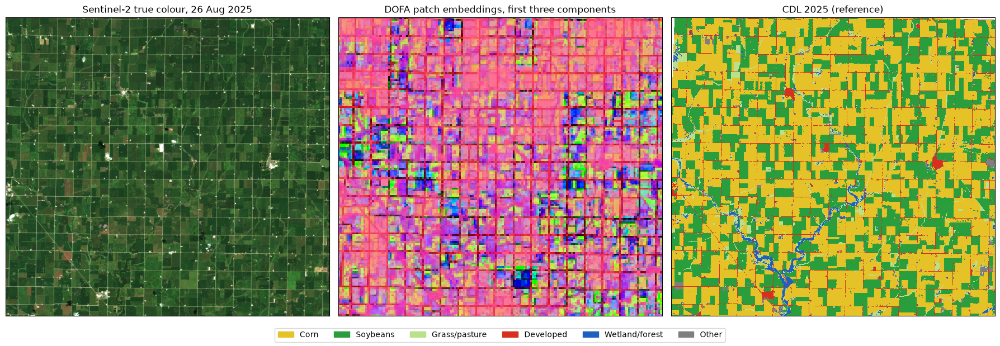

In [9]:
mean = np.array([s2[i][valid].mean() for i in range(len(S2_BANDS))], "float32")[:, None, None]  # band means
std = np.array([s2[i][valid].std() for i in range(len(S2_BANDS))], "float32")[:, None, None]  # band std
z = np.where(valid, (s2 - mean) / std, 0).astype("float32")  # standardised scene, no data -> 0
# cut the scene into tiles of TILE x TILE px
tiles = z.reshape(len(S2_BANDS), NTR, TILE, NTC, TILE).transpose(1, 3, 0, 2, 4).reshape(-1, len(S2_BANDS), TILE, TILE)
p_idx = [S2_BANDS.index(b) for b in PRITHVI_BANDS]  # Prithvi's bands within the ten


def embed_tiles(fn, band_idx, batch=8):  # embed every tile and arrange the tokens on the patch grid
    out = []  # tokens of every batch
    for i in range(0, len(tiles), batch):  # batches of tiles
        x = torch.from_numpy(tiles[i:i + batch][:, band_idx]).to(DEVICE)  # the tiles on the GPU
        out.append(fn(x).float().cpu().numpy())  # (b, 196, D)
    t = np.concatenate(out)  # (tile, 196, D)
    D = t.shape[-1]  # embedding size
    # (tile row, tile col, patch row, patch col, D) -> (patch row, patch col, D) over the whole area
    t = t.reshape(NTR, NTC, G, G, D).transpose(0, 2, 1, 3, 4).reshape(NPR * NPC, D)
    return t  # tokens of the tile


t0 = time.time()  # start the timer
emb = {"Mean spectrum": s2.reshape(len(S2_BANDS), NPR, PATCH, NPC, PATCH).mean(axis=(2, 4)).reshape(len(S2_BANDS), -1).T}  # baseline: mean spectrum of each patch
# DOFA embeddings, told the wavelength of every band
emb["DOFA"] = embed_tiles(lambda x: dofa_tokens(x, list(WAVELENGTHS.values())), list(range(len(S2_BANDS))))
emb["Prithvi-EO-2.0"] = embed_tiles(prithvi_tokens, p_idx)  # Prithvi tokens
print(f"embeddings in {time.time() - t0:.0f} s:", {k: v.shape for k, v in emb.items()})  # run time and sizes

from sklearn.decomposition import PCA  # principal components for display
pcs = PCA(3, random_state=SEED).fit_transform(emb["DOFA"])  # three components of the DOFA embeddings
lo, hi = np.percentile(pcs, [2, 98], axis=0)  # 2-98 % stretch
COLORS = ["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#1f5fbf", "#7f7f7f"]  # class colours
cmap_cls = ListedColormap(COLORS)  # colour map of the classes
rgb = np.clip(s2[[2, 1, 0]].transpose(1, 2, 0) / 0.15, 0, 1)  # true colour, 0-15 % reflectance
fig, ax = plt.subplots(1, 3, figsize=(18, 6))  # three panels
ax[0].imshow(rgb); ax[0].set_title("Sentinel-2 true colour, 26 Aug 2025")  # the scene
ax[1].imshow(np.clip((pcs - lo) / (hi - lo), 0, 1).reshape(NPR, NPC, 3), interpolation="nearest")  # embeddings
ax[1].set_title("DOFA patch embeddings, first three components")  # title
ax[2].imshow(np.ma.masked_less(cdl, 0), cmap=cmap_cls, vmin=-0.5, vmax=5.5, interpolation="nearest")  # reference
ax[2].set_title("CDL 2025 (reference)")  # title
for a in ax:  # every panel
    a.set_xticks([]); a.set_yticks([])  # no ticks
# class legend
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="lower center", ncol=6)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()  # arrange and draw

### Find similar places with `embedding_search`

`embedding_search` returns the `k` nearest neighbours of a query embedding by cosine similarity. With a foundation model this becomes a "find more places like this one" tool: click one example, get candidates across the scene. Two queries are taken from the western half, a patch in a town (CDL "developed") and a patch of a stream corridor ("wetland/forest"), and the 50 most similar patches are searched in the eastern half. Each result is checked against the CDL: **precision** is the share of the 50 results whose CDL class matches the query's, and the **base rate** is the share of that class among all eastern patches, the precision a random pick would have.


In [10]:
queries = {}  # class -> query patch index
for k in (3, 4):  # developed, wetland/forest
    cand = np.flatnonzero(~east & (p_label == k) & (p_purity >= 0.8))  # pure western patches of the class
    queries[CLASSES[k]] = int(cand[np.argmax(p_purity[cand])])  # the purest one
search_rows, hits = [], {}  # scores and the retrieved patches
pool = np.flatnonzero(east & (p_purity >= 0.6))  # eastern patches with a label
for cname, q in queries.items():  # each query
    k = CLASSES.index(cname)  # its class
    for name, E in emb.items():  # each feature set
        idx, sim = ic.embedding_search(E[pool], E[q], k=50, metric="cosine")  # 50 nearest neighbours
        found = pool[idx[0]]  # their patch indices
        hits[cname, name] = found  # keep them for the map
        search_rows.append({"query": cname, "features": name, "precision@50": np.mean(p_label[found] == k),  # precision of the search and the base rate
                            "base rate": np.mean(p_label[pool] == k), "mean similarity": float(sim.mean())})
search_table = pd.DataFrame(search_rows).set_index(["query", "features"]).round(3)  # as a table
search_table  # show it

precision@50  base rate  mean similarity
query          features                                                
Developed      Mean spectrum           0.30      0.004            0.999
               DOFA                    0.38      0.004            0.974
               Prithvi-EO-2.0          0.22      0.004            0.751
Wetland/forest Mean spectrum           0.08      0.003            1.000
               DOFA                    0.08      0.003            0.950
               Prithvi-EO-2.0          0.02      0.003            0.921

The map shows the query patch (white square) and its 50 nearest DOFA neighbours (circles) on the true-colour image, with the CDL behind. Retrieved patches that look like the query but are not the same land cover (for example farmsteads with trees and buildings returned for a town query) are the typical failure: the search returns what *looks* similar to the model, which is not always the class you had in mind.


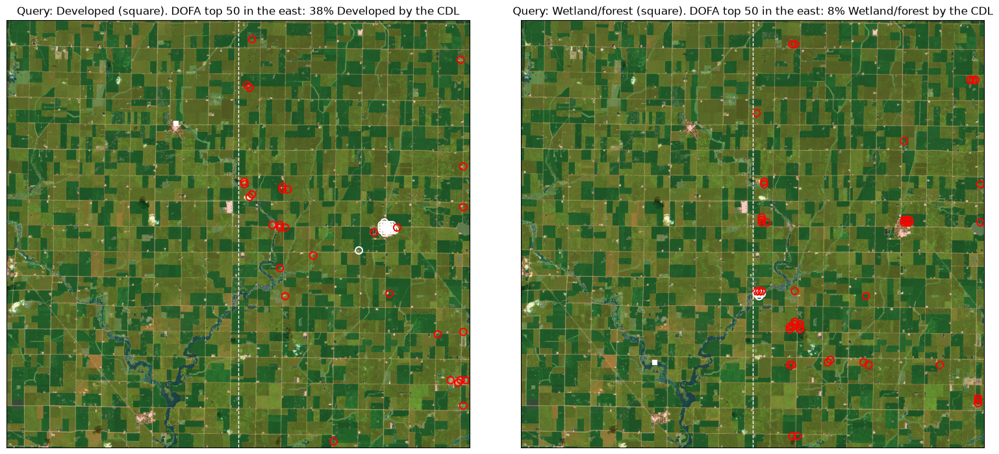

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))  # one panel per query
for a, (cname, q) in zip(ax, queries.items()):  # each query
    a.imshow(rgb)  # true colour
    a.imshow(np.ma.masked_less(cdl, 0), cmap=cmap_cls, vmin=-0.5, vmax=5.5, alpha=0.25, interpolation="nearest")  # CDL
    found = hits[cname, "DOFA"]  # the DOFA results
    ok = p_label[found] == CLASSES.index(cname)  # correct by the CDL
    for sel, colour in ((ok, "white"), (~ok, "red")):  # correct in white, wrong in red
        # mark the patches the search found
        a.scatter(pcol[found[sel]] * PATCH + PATCH / 2, prow[found[sel]] * PATCH + PATCH / 2, s=60,
                  facecolors="none", edgecolors=colour, linewidths=1.5)  # circles at the patch centres
    a.add_patch(plt.Rectangle((pcol[q] * PATCH, prow[q] * PATCH), PATCH, PATCH, fill=False, ec="white", lw=3))  # query
    a.axvline(NPC // 2 * PATCH, color="white", ls="--", lw=1)  # boundary of the searched half
    a.set_title(f"Query: {cname} (square). DOFA top 50 in the east: {ok.mean():.0%} {cname} by the CDL")  # title
    a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

### Five labels per class with `few_shot_prototypes`

`few_shot_prototypes` is the simplest few-shot classifier: the **prototype** of a class is the mean embedding of its labelled examples, and every query patch takes the class of the most similar prototype (cosine similarity). Five pure patches per class are drawn from the western half, all labelled eastern patches are classified, and the result is scored against the CDL with `classification_report`. One draw of five examples can be lucky or unlucky, so the draw is repeated 30 times and the mean and spread are reported. The first table shows how the scores change with 20 and 50 labels per class; the second gives the five-label case with its spread.


In [12]:
names = dict(enumerate(CLASSES))  # class id -> name
support_pool = {k: np.flatnonzero(~east & (p_label == k) & (p_purity >= 0.8)) for k in range(len(CLASSES))}  # pure west
query_idx = np.flatnonzero(east & (p_purity >= 0.6))  # labelled east patches
shot_rows = []  # one row per draw, shot count and feature set
for n_shot in (5, 20, 50):  # labels per class
    for draw in range(30):  # 30 random draws of the support set
        r = np.random.default_rng(SEED + draw)  # generator of this draw
        # n_shot random support patches per class
        support = np.concatenate([r.choice(support_pool[k], min(n_shot, len(support_pool[k])), replace=False)
                                  for k in range(len(CLASSES))])  # n_shot per class (fewer if a class has fewer)
        for name, E in emb.items():  # each feature set
            pred, _ = ic.few_shot_prototypes(E[support], p_label[support], E[query_idx])  # nearest prototype
            rep = ic.classification_report(p_label[query_idx], pred, labels=list(range(len(CLASSES))))  # scores
            shot_rows.append({"features": name, "labels per class": n_shot, "draw": draw,  # one result row
                              "overall accuracy": rep["overall_accuracy"], "macro F1": rep["macro_f1"]})
shots = pd.DataFrame(shot_rows)  # as a table
five = shots[shots["labels per class"] == 5]  # the five-label case
few_shot_table = five.groupby("features")[["overall accuracy", "macro F1"]].agg(["mean", "std"]).round(3)  # summary
print("pure western patches available per class:", {CLASSES[k]: len(v) for k, v in support_pool.items()})  # the limit
display(shots.groupby(["labels per class", "features"])[["overall accuracy", "macro F1"]].mean().unstack(0).round(3))  # mean scores per label count
print(f"{len(query_idx)} eastern patches classified (30 draws per setting); "  # test size and class shares
      f"corn {np.mean(p_label[query_idx] == 0):.1%}, corn + soybeans {np.mean(p_label[query_idx] <= 1):.1%} of them")
few_shot_table  # show it

pure western patches available per class: {'Corn': 6603, 'Soybeans': 4080, 'Grass/pasture': 176, 'Developed': 55, 'Wetland/forest': 91, 'Other': 33}


overall accuracy               macro F1              
labels per class               5      20     50       5      20     50
features                                                              
DOFA                        0.433  0.562  0.613    0.246  0.306  0.346
Mean spectrum               0.461  0.506  0.501    0.312  0.305  0.301
Prithvi-EO-2.0              0.636  0.690  0.683    0.371  0.378  0.370

13463 eastern patches classified (30 draws per setting); corn 59.3%, corn + soybeans 97.9% of them


overall accuracy        macro F1       
                           mean    std     mean    std
features                                              
DOFA                      0.433  0.074    0.246  0.036
Mean spectrum             0.461  0.078    0.312  0.049
Prithvi-EO-2.0            0.636  0.084    0.371  0.039

**Reading the few-shot results.** With five labels per class, DOFA and the mean spectrum stay below the accuracy of calling every patch corn (59 % of the eastern patches, printed above the tables), and Prithvi only just passes it. DOFA does no better than the plain mean spectrum. The failure is the same for all of them: the eastern half is almost entirely corn and soybeans, and five examples of each small class (grass, developed, wetland/forest, other) form prototypes that attract thousands of crop patches, especially those along roads and field edges. More labels help DOFA most (from 43 % to about 61 % with 50 per class) and Prithvi a little, while the mean spectrum does not improve at all. Whatever the features, the prototype classifier never learns that the small classes are rare. The map shows one five-label draw of the DOFA classifier next to the CDL: many crop fields are grey ("other") or blue (wetland/forest), and the section-road grid is mapped as developed.


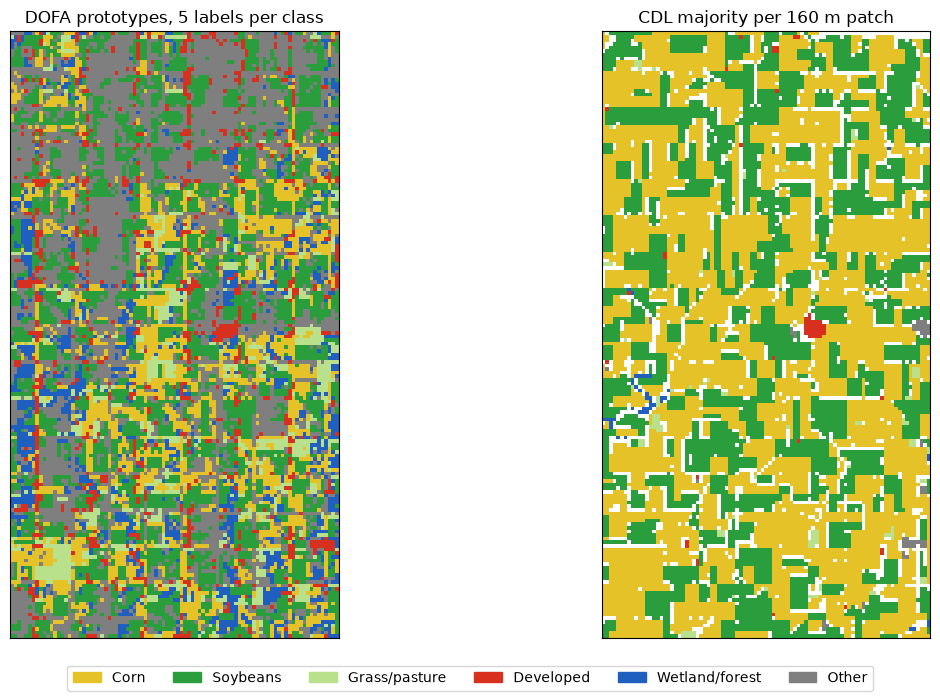

In [13]:
r = np.random.default_rng(SEED)  # the first draw again
support = np.concatenate([r.choice(support_pool[k], 5, replace=False) for k in range(len(CLASSES))])  # 5 per class
pred_all, sim_all = ic.few_shot_prototypes(emb["DOFA"][support], p_label[support], emb["DOFA"])  # every patch
fewshot_map = pred_all.reshape(NPR, NPC).astype("float32")  # as a patch map
fewshot_map[~east.reshape(NPR, NPC)] = np.nan  # show the eastern (test) half only
ref_map = np.where(p_purity >= 0.6, p_label, -1).reshape(NPR, NPC).astype("float32")  # CDL majority per patch
ref_map[(ref_map < 0) | ~east.reshape(NPR, NPC)] = np.nan  # same area, labelled patches only
fig, ax = plt.subplots(1, 2, figsize=(14, 7))  # two panels
# few-shot map next to the reference map
for a, m, t in zip(ax, (fewshot_map, ref_map), ("DOFA prototypes, 5 labels per class", "CDL majority per 160 m patch")):
    a.imshow(m[:, NPC // 2:], cmap=cmap_cls, vmin=-0.5, vmax=5.5, interpolation="nearest")  # eastern half
    a.set_title(t); a.set_xticks([]); a.set_yticks([])  # title, no ticks
# class legend
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="lower center", ncol=6)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()  # arrange and draw

### Few-shot land use on the UB campus

The UB image is 170 × 210 pixels of 10 m, smaller than one ViT tile and far coarser than the buildings, lawns and parking lots it is labelled with. To get one embedding per pixel, the image is upsampled four times, padded to whole 224-pixel tiles, embedded with DOFA, and the 56 × 56 token grid is interpolated back to the 10 m pixels: each pixel then carries a 768-number description of its 40 m neighbourhood. The baseline is the pixel's own ten-band spectrum.

The labelled points come from 113 digitised polygons, and neighbouring points of one polygon are nearly identical. To keep the test honest, the five support points per class are drawn from the `train_data` points, and only `test_data` points that lie in **other polygons** than the support points are scored.


In [14]:
import geopandas as gpd  # vector data (the labelled polygons)

UB_BANDS = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]  # same order as S2_BANDS
with rasterio.open(UB_DIR / "Images" / "B2.tif") as src:  # georeference of the UB image
    ub_transform = src.transform  # pixel -> UTM 17N
ub = np.stack([rasterio.open(UB_DIR / "Images" / f"{b}.tif").read(1) for b in UB_BANDS]).astype("float32")  # (10, y, x)
ub_z = (ub - ub.mean(axis=(1, 2), keepdims=True)) / ub.std(axis=(1, 2), keepdims=True)  # standardise per band

up = torch.nn.functional.interpolate(torch.from_numpy(ub_z)[None], scale_factor=4, mode="bilinear")[0]  # x4 upsample
ph, pw = -up.shape[1] % TILE, -up.shape[2] % TILE  # padding to whole tiles
up = torch.nn.functional.pad(up[None], (0, pw, 0, ph), mode="reflect")[0]  # (10, 896, 896)
nr, nc = up.shape[1] // TILE, up.shape[2] // TILE  # tiles per side
t = up.reshape(10, nr, TILE, nc, TILE).permute(1, 3, 0, 2, 4).reshape(-1, 10, TILE, TILE).to(DEVICE)  # the tiles
tok = dofa_tokens(t, list(WAVELENGTHS.values()))  # (tile, 196, 768)
tok = tok.reshape(nr, nc, G, G, -1).permute(4, 0, 2, 1, 3).reshape(1, -1, nr * G, nc * G)  # (1, 768, 56, 56)
tok = tok[..., : (ub.shape[1] * 4) // PATCH + 1, : (ub.shape[2] * 4) // PATCH + 1]  # drop the padding
ub_feat = torch.nn.functional.interpolate(tok, size=ub.shape[1:], mode="bilinear")[0].cpu().numpy()  # (768, y, x)

pts = {s: pd.read_csv(UB_DIR / "Label_Point_Data" / f"{s}_data.csv") for s in ("train", "test")}  # labelled points
polys = gpd.read_file(UB_DIR / "Label_Point_Data" / "GroundTruth_data.shp").reset_index(names="polygon")  # polygons
for s, df in pts.items():  # attach the polygon and the pixel of every point
    g = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.x, df.y))  # points (same UTM coordinates)
    # polygon that holds each point
    df["polygon"] = gpd.sjoin(g, polys[["polygon", "geometry"]], how="left", predicate="within")["polygon"].groupby(level=0).first()
    df["col"], df["row"] = (~ub_transform * (df.x.values, df.y.values))  # map -> pixel coordinates
    # pixel row and column inside the image
    df["row"], df["col"] = df.row.astype(int).clip(0, ub.shape[1] - 1), df.col.astype(int).clip(0, ub.shape[2] - 1)
UB_CLASSES = pts["train"].groupby("Class_ID").Landuse.first().to_dict()  # class id -> land use
print("UB classes:", UB_CLASSES, "| points:", {s: len(d) for s, d in pts.items()})  # classes and point counts

UB classes: {1: 'Parking/road/pavement', 2: 'Building', 3: 'Tree/bushes', 4: 'Grass', 5: 'Water'} | points: {'train': 16764, 'test': 7181}


The result is scored on test points from polygons the support points did not come from. On this campus, the pixel's own spectrum beats the DOFA features. The objects are small (buildings, lawns and parking lots are 10 m to 50 m across), so a 40 m neighbourhood blurs them together, and DOFA's input here is an upsampled 10 m image, finer than anything in the original pixels. Context from a foundation model helps where an object is larger than a pixel and its surroundings say what it is; at 10 m on a campus, it does not.


In [15]:
ub_rows = []  # one row per draw and feature set
for draw in range(30):  # 30 random draws
    r = np.random.default_rng(SEED + draw)  # generator of this draw
    tr = pts["train"].dropna(subset=["polygon"])  # training points inside a polygon
    # five support points per class
    sup = pd.concat([tr[tr.Class_ID == k].iloc[r.choice((tr.Class_ID == k).sum(), 5, replace=False)] for k in UB_CLASSES])
    te = pts["test"][~pts["test"].polygon.isin(sup.polygon) & pts["test"].polygon.notna()]  # other polygons only
    for name, F in {"10-band spectrum": ub, "DOFA (40 m context)": ub_feat}.items():  # each feature set
        S, Q = F[:, sup.row, sup.col].T, F[:, te.row, te.col].T  # support and query features
        pred, _ = ic.few_shot_prototypes(S, sup.Class_ID.values, Q)  # nearest prototype
        rep = ic.classification_report(te.Class_ID.values, pred, labels=list(UB_CLASSES))  # scores
        ub_rows.append({"features": name, "overall accuracy": rep["overall_accuracy"], "macro F1": rep["macro_f1"],  # one result row
                        "test points": len(te)})
ub_table = pd.DataFrame(ub_rows).groupby("features").agg(["mean", "std"]).round(3)  # summary of 30 draws
ub_table  # show it

overall accuracy        macro F1        test points  \
                                mean    std     mean    std        mean   
features                                                                  
10-band spectrum               0.584  0.062    0.581  0.058    4059.067   
DOFA (40 m context)            0.514  0.066    0.483  0.067    4059.067   

                              
                         std  
features                      
10-band spectrum     304.204  
DOFA (40 m context)  304.204

## Promptable segmentation

### SAM from points and boxes

Segment Anything (Kirillov et al. 2023) cuts out the object under a prompt: one or more points, or a box. It was trained on 11 million everyday photographs and has no notion of land cover: it returns *an* object boundary, not a class. `sam_segment` runs SAM through segment-geospatial on a GeoTIFF and writes the mask as a GeoTIFF with the same grid. DeepGlobe tiles are plain JPEG files without coordinates, so each tile is written as a GeoTIFF with a pixel-unit grid (no CRS), and prompts are given in pixel coordinates.

Three tiles are used, one each for water, forest and urban land, chosen so that the class covers 15 % to 50 % of the tile: a distinct object rather than the whole image. In each, the largest connected patch of that class in the reference mask is the target. The point prompt is the target's most interior pixel (farthest from both its edge and the tile border); the box prompt is its bounding box. The **intersection over union (IoU)** between SAM's mask and the target measures the agreement (1 = identical).


In [16]:
# land-cover classes of the tiles
LC_CLASSES = ["urban_land", "agriculture_land", "rangeland", "forest_land", "water", "barren_land", "unknown"]
LC_RGB = pd.read_csv(LC_DIR / "class_dict.csv").set_index("name").loc[LC_CLASSES][["r", "g", "b"]].values  # mask colours


def lc_mask(tile_id):  # DeepGlobe reference mask as class indices
    m = np.asarray(Image.open(LC_DIR / "train" / f"{tile_id}_mask.png").convert("RGB")).astype(int)  # RGB mask
    out = np.full(m.shape[:2], 6, "int8")  # unknown by default
    for k, c in enumerate(LC_RGB):  # every class colour
        out[np.abs(m - c).sum(axis=-1) < 60] = k  # tolerate JPEG-like noise in the PNG
    return out  # the result


def lc_geotiff(tile_id):  # DeepGlobe JPEG -> GeoTIFF on a pixel grid (no CRS: the tiles have no location)
    im = np.asarray(Image.open(LC_DIR / "train" / f"{tile_id}_sat.jpg").convert("RGB"))  # (y, x, 3)
    path = OUTPUT_DIR / f"deepglobe_{tile_id}.tif"  # output file
    # write the RGB tile as a GeoTIFF
    with rasterio.open(path, "w", driver="GTiff", height=im.shape[0], width=im.shape[1], count=3, dtype="uint8",
                       transform=Affine(1, 0, 0, 0, -1, im.shape[0])) as dst:  # one unit per pixel, north up
        dst.write(im.transpose(2, 0, 1))  # bands first
    return path, im  # file and image


def iou(a, b):  # intersection over union of two boolean masks
    return float((a & b).sum() / max((a | b).sum(), 1))  # IoU of two boolean masks


fracs = {}  # class shares of every training tile (on every 8th pixel, for speed)
for f in sorted((LC_DIR / "train").glob("*_mask.png")):  # every reference mask
    tid = f.name.split("_")[0]  # tile id
    m = lc_mask(tid)[::8, ::8]  # thinned mask
    fracs[tid] = [np.mean(m == k) for k in range(len(LC_CLASSES))]  # class shares
fracs = pd.DataFrame(fracs, index=LC_CLASSES).T  # tile x class
SAM_TILES = {}  # class -> tile used for the prompts
for c in ("water", "forest_land", "urban_land"):  # each class
    cand = fracs.index[(fracs[c] >= 0.15) & (fracs[c] <= 0.5)]  # tiles where the class is a distinct object
    # largest patch of each class per tile
    biggest = {t: np.bincount(ndimage.label(lc_mask(t)[::8, ::8] == LC_CLASSES.index(c))[0].ravel())[1:].max()
               for t in cand}  # size of the largest connected patch in each candidate tile
    SAM_TILES[c] = max(biggest, key=biggest.get)  # the tile with the largest single patch
print("tiles used:", SAM_TILES)  # chosen tiles

tiles used: {'water': '194156', 'forest_land': '176225', 'urban_land': '435277'}


In [17]:
sam_rows, sam_show = [], {}  # scores and figure data
for cname, tid in SAM_TILES.items():  # each class and its tile
    k = LC_CLASSES.index(cname)  # class index
    tif, im = lc_geotiff(tid)  # tile as GeoTIFF
    lab, n = ndimage.label(lc_mask(tid) == k)  # connected patches of the class
    target = lab == (np.bincount(lab.ravel())[1:].argmax() + 1)  # the largest one
    dist = ndimage.distance_transform_edt(np.pad(target, 1))[1:-1, 1:-1]  # distance to the patch edge or the tile border
    py, px = np.unravel_index(dist.argmax(), dist.shape)  # most interior pixel
    ys, xs = np.nonzero(target)  # pixels of the patch
    box = [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]  # its bounding box (x0, y0, x1, y1)
    masks = {}  # SAM masks per prompt type
    # a point prompt and a box prompt
    for prompt, kw in (("point", {"points": [[int(px), int(py)]], "point_labels": [1]}), ("box", {"boxes": [box]})):
        out = OUTPUT_DIR / f"sam_{prompt}_{tid}.tif"  # mask file
        res = ic.sam_segment(tif, out, model="sam", model_type="vit_h", **kw)  # SAM ViT-H
        masks[prompt] = rasterio.open(res["mask"]).read(1) > 0  # boolean mask
        sam_rows.append({"class": cname, "tile": tid, "prompt": prompt, "IoU with reference": iou(masks[prompt], target),  # IoU and areas of this prompt
                         "SAM area %": 100 * masks[prompt].mean(), "reference area %": 100 * target.mean(),
                         "verified": res["verified"]})
    sam_show[cname] = (im, target, (px, py), box, masks)  # for the figure
sam_table = pd.DataFrame(sam_rows).set_index(["class", "prompt"]).round(3)  # as a table
sam_table  # show it

tile  IoU with reference  SAM area %  reference area %  \
class       prompt                                                             
water       point   194156               0.964      45.318            47.002   
            box     194156               0.980      46.070            47.002   
forest_land point   176225               0.255      12.862            50.099   
            box     176225               0.773      61.722            50.099   
urban_land  point   435277               0.833      53.540            44.903   
            box     435277               0.520      86.261            44.903   

                    verified  
class       prompt            
water       point      False  
            box        False  
forest_land point      False  
            box        False  
urban_land  point      False  
            box        False

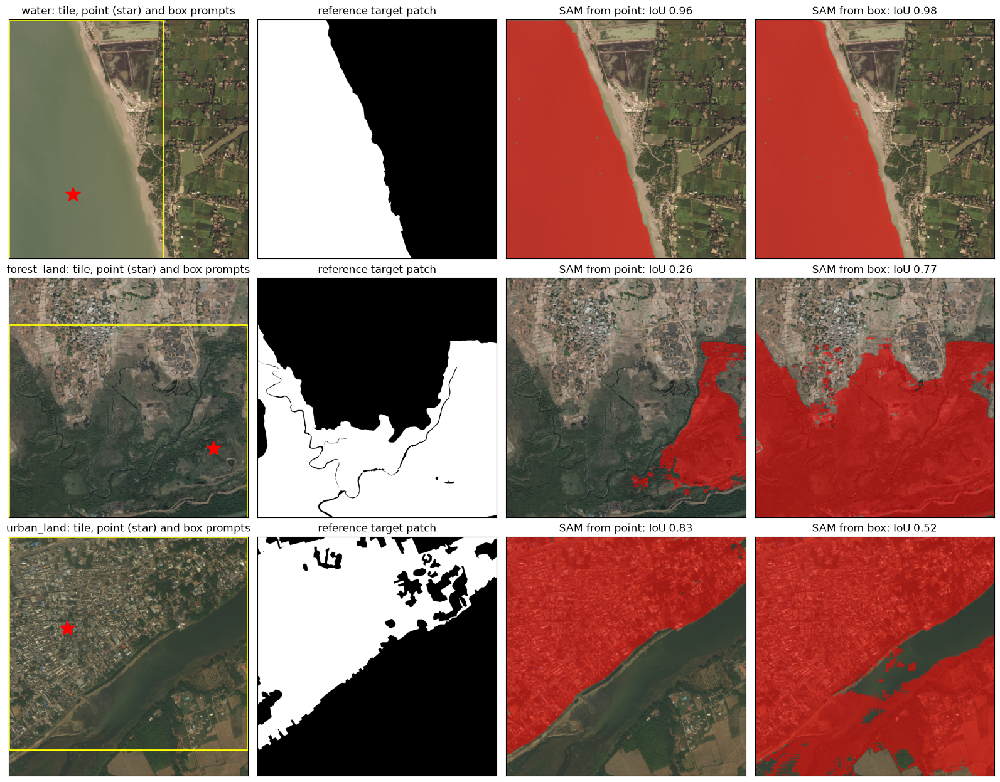

In [18]:
fig, ax = plt.subplots(len(sam_show), 4, figsize=(16, 4.2 * len(sam_show)))  # one row per class
for r, (cname, (im, target, (px, py), box, masks)) in enumerate(sam_show.items()):  # each class
    ax[r, 0].imshow(im); ax[r, 0].plot(px, py, "r*", ms=18)  # tile and point prompt
    ax[r, 0].add_patch(plt.Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, ec="yellow", lw=2))  # box
    ax[r, 0].set_title(f"{cname}: tile, point (star) and box prompts")  # title
    ax[r, 1].imshow(target, cmap="gray"); ax[r, 1].set_title("reference target patch")  # reference
    for c, prompt in ((2, "point"), (3, "box")):  # the two SAM masks
        ax[r, c].imshow(im); ax[r, c].imshow(np.ma.masked_equal(masks[prompt], 0), cmap="autumn", alpha=0.55)  # overlay
        ax[r, c].set_title(f"SAM from {prompt}: IoU {iou(masks[prompt], target):.2f}")  # title with the score
for a in ax.ravel():  # every panel
    a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

**Reading the SAM results.** The sea, a large uniform area with one sharp edge, is segmented almost perfectly from either prompt. The forest is not: a point inside it selects only the lighter, more open stand around the point (IoU about 0.26), and only the box makes SAM take most of the forest, while spilling into the edge of the village. For the town, the point does better than the box: the box spans the town and the river below it, and SAM fills most of the box, river and far bank included. What SAM returns follows the visual edges near the prompt, not the land-cover class.


### Segment from words with `text_prompt_segment`

`text_prompt_segment` chains Grounding DINO (Liu et al. 2023), which finds boxes for a phrase, with SAM, which turns each box into a mask (the LangSAM pipeline of segment-geospatial). The phrases "water", "forest" and "building" are tried on the same three tiles, and "water" is also tried on a tile that is almost entirely farmland and has **no water at all**. The score is the IoU with the reference mask of the matching class over the whole tile.

`groundingdino-py` was written for `transformers` 4. In `transformers` 5 the BERT model no longer has three helper methods it calls, so the cell first adds them back in their version-4 form. This only restores old behaviour for this session; nothing is installed or changed on disk.


In [19]:
from transformers import BertModel  # the text encoder used by Grounding DINO


def _extended_mask(self, attention_mask, input_shape=None, device=None, dtype=None):  # transformers 4 behaviour
    dtype = dtype or next(self.parameters()).dtype  # model precision
    m = attention_mask[:, None, None, :] if attention_mask.dim() == 2 else attention_mask[:, None, :, :]  # broadcastable
    return (1.0 - m.to(dtype)) * torch.finfo(dtype).min  # 0 where attended, very negative where masked


def _head_mask(self, head_mask, num_layers, is_attention_chunked=False):  # transformers 4 behaviour
    return [None] * num_layers if head_mask is None else head_mask  # no head masking


for name, fn in (("get_extended_attention_mask", _extended_mask),  # add the missing helpers only
                 ("invert_attention_mask", lambda self, m: _extended_mask(self, m)),
                 ("get_head_mask", _head_mask)):
    if not hasattr(BertModel, name):  # absent in transformers 5
        setattr(BertModel, name, fn)  # restore it for this session

# (class, phrase, tile) for the text-prompt tests
TEXT_TESTS = [(c, p, tid) for (c, p), tid in zip([("water", "water"), ("forest_land", "forest"), ("urban_land", "building")],
                                                SAM_TILES.values())]  # class, phrase, tile
farm_tile = fracs["agriculture_land"].idxmax()  # the most agricultural tile
TEXT_TESTS.append(("water", "water", farm_tile))  # the absent-class test
text_rows, text_show = [], []  # scores and figure data
for cname, phrase, tid in TEXT_TESTS:  # each test
    tif, im = lc_geotiff(tid)  # tile as GeoTIFF
    ref_mask = lc_mask(tid) == LC_CLASSES.index(cname)  # reference mask of the class
    t0 = time.time()  # start the timer
    # text-prompted segmentation of the tile
    res = ic.text_prompt_segment(tif, phrase, OUTPUT_DIR / f"text_{phrase}_{tid}.tif",
                                 box_threshold=0.24, text_threshold=0.24)  # Grounding DINO + SAM
    pred = rasterio.open(res["mask"]).read(1) > 0  # boolean mask
    text_rows.append({"prompt": phrase, "tile": tid, "reference class": cname, "reference area %": 100 * ref_mask.mean(),  # IoU and areas of this phrase
                      "predicted area %": 100 * pred.mean(), "IoU": iou(pred, ref_mask), "seconds": time.time() - t0,
                      "verified": res["verified"]})
    text_show.append((phrase, tid, im, ref_mask, pred))  # for the figure
text_table = pd.DataFrame(text_rows).round(3)  # as a table
text_table  # show it

final text_encoder_type: bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

final text_encoder_type: bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

final text_encoder_type: bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

final text_encoder_type: bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,prompt,tile,reference class,reference area %,predicted area %,IoU,seconds,verified
0,water,194156,water,47.002,46.426,0.987,5.564,False
1,forest,176225,forest_land,50.099,99.380,0.495,5.753,False
2,building,435277,urban_land,46.334,55.580,0.801,5.376,False
3,water,277644,water,0.000,98.134,0.000,5.623,False


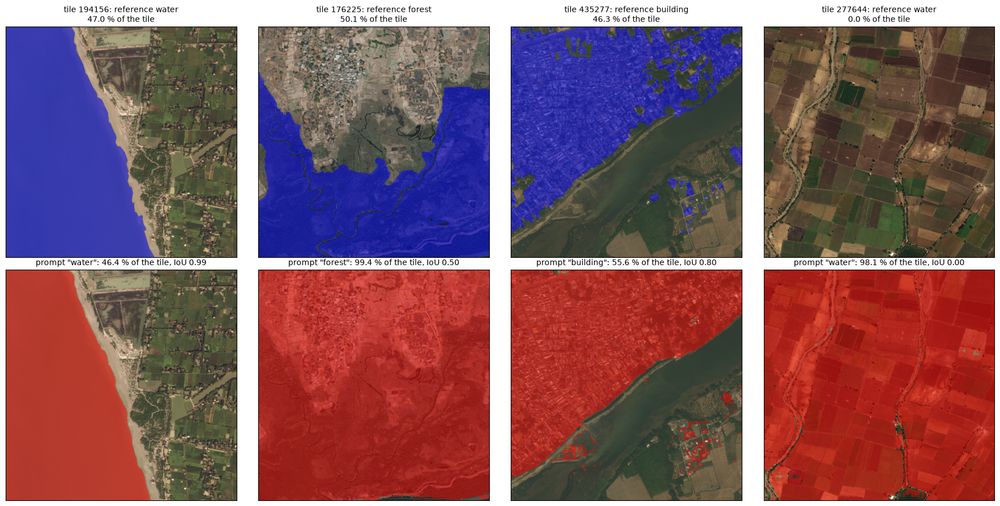

In [20]:
fig, ax = plt.subplots(2, len(text_show), figsize=(4.5 * len(text_show), 9))  # reference above, prediction below
for c, (phrase, tid, im, ref_mask, pred) in enumerate(text_show):  # each test
    ax[0, c].imshow(im); ax[0, c].imshow(np.ma.masked_equal(ref_mask, 0), cmap="winter", alpha=0.5)  # reference
    # reference mask title
    ax[0, c].set_title(f"tile {tid}: reference {phrase}\n{100 * ref_mask.mean():.1f} % of the tile", fontsize=10)
    ax[1, c].imshow(im); ax[1, c].imshow(np.ma.masked_equal(pred, 0), cmap="autumn", alpha=0.5)  # prediction
    # prediction title with its IoU
    ax[1, c].set_title(f'prompt "{phrase}": {100 * pred.mean():.1f} % of the tile, IoU {iou(pred, ref_mask):.2f}', fontsize=10)
for a in ax.ravel():  # every panel
    a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

**Reading the text-prompt results.** "water" on the coastal tile is nearly perfect. "forest" returns the whole tile, village and fields included, so its IoU is only about 0.5 although the forest is inside the mask. "building" covers the town well (IoU 0.80) because the reference labels the whole built-up area as urban land, gaps between houses included. On the farmland tile without any water, "water" still masks 98 % of the tile: Grounding DINO always returns its best-matching boxes, however weak, and SAM fills them. The pipeline has no way to answer "not present".


## Zero-shot classification

### RemoteCLIP on DeepGlobe crops

CLIP-style models embed an image and a sentence into the same space; an image is assigned to the class whose sentence is most similar. RemoteCLIP (Liu et al. 2024) and GeoRSCLIP (Zhang et al. 2024) are CLIP models retrained on remote sensing image-caption pairs. `load_rs_clip` downloads one from Hugging Face and returns the model, its image preprocessing and its tokenizer; passing that tuple to `zero_shot_classify` avoids reloading it for every call.

The test set is cut from 150 random DeepGlobe training tiles: each tile is split into 4 × 4 crops of 612 pixels (306 m), and a crop is kept when one class covers at least 70 % of it; that class is its reference label. No DeepGlobe label is used to build the classifier: only the class names. When `load_rs_clip` creates the empty ViT-B/32 architecture, `open_clip` prints "No pretrained weights loaded ... initialized randomly"; the RemoteCLIP checkpoint is loaded right after that (all 302 weight tensors match), so the warning can be ignored here.


In [21]:
for m in ("dofa", "prithvi"):  # free the encoders before loading CLIP
    globals().pop(m, None)  # drop the reference
torch.cuda.empty_cache()  # release the GPU memory

t0 = time.time()  # start the timer
remoteclip = ic.load_rs_clip("remoteclip-vit-b-32", device=DEVICE)  # (model, preprocess, tokenizer)
print(f"RemoteCLIP ViT-B/32 loaded in {time.time() - t0:.0f} s")  # load time

CROP = 612  # crop size in pixels (2448 / 4)
crops, crop_y, crop_tile = [], [], []  # images, labels and source tiles
for tid in rng.choice(fracs.index.values, 150, replace=False):  # 150 random tiles
    im = np.asarray(Image.open(LC_DIR / "train" / f"{tid}_sat.jpg").convert("RGB"))  # the tile
    m = lc_mask(tid)  # its reference mask
    for r in range(4):  # crop rows
        for c in range(4):  # crop columns
            mc = m[r * CROP:(r + 1) * CROP, c * CROP:(c + 1) * CROP]  # mask of the crop
            share = np.bincount(mc.ravel(), minlength=7) / mc.size  # class shares
            if share[:6].max() >= 0.7:  # dominated by one real class
                crops.append(im[r * CROP:(r + 1) * CROP, c * CROP:(c + 1) * CROP])  # keep the crop
                crop_y.append(int(share[:6].argmax())); crop_tile.append(tid)  # its label and tile
crop_y = np.array(crop_y)  # labels as an array
print(f"{len(crops)} crops:", pd.Series(crop_y).map(dict(enumerate(LC_CLASSES))).value_counts().to_dict())  # crops per class


def zero_shot(model, class_names, template, batch=256):  # zero-shot predictions in batches
    # classify the crops batch by batch
    parts = [ic.zero_shot_classify(crops[i:i + batch], class_names, model=model, template=template)
             for i in range(0, len(crops), batch)]  # one table per batch
    return pd.concat(parts, ignore_index=True)  # all crops

RemoteCLIP ViT-B/32 loaded in 1 s


1887 crops: {'agriculture_land': 1332, 'forest_land': 176, 'urban_land': 157, 'rangeland': 83, 'barren_land': 82, 'water': 57}


### Prompt wording effects

The classifier is only the sentences, so their wording is a hyperparameter. Two sets of class names are compared, the dataset's own names ("urban land", "agriculture land", ...) and plain descriptions ("buildings and roads", "farmland", ...), each inside four sentence templates. Every combination is scored on the same crops. The spread of the table is the point: nothing changed but the words.


In [22]:
NAME_SETS = {  # two ways of naming the six classes, in LC_CLASSES order
    "dataset names": ["urban land", "agriculture land", "rangeland", "forest land", "water", "barren land"],
    "plain descriptions": ["buildings and roads", "farmland", "grassland and shrubs", "forest", "a lake or river", "bare soil"],
}
# prompt templates to compare
TEMPLATES = ["a satellite image of {}.", "an aerial photograph of {}.", "{}", "a remote sensing image showing {}."]
prompt_rows, preds = [], {}  # scores and predictions
for set_name, cls_names in NAME_SETS.items():  # each naming
    for template in TEMPLATES:  # each sentence template
        df = zero_shot(remoteclip, cls_names, template)  # classify every crop
        y_pred = np.array([cls_names.index(p) for p in df.prediction])  # predicted class index
        rep = ic.classification_report(crop_y, y_pred, labels=list(range(6)))  # scores
        prompt_rows.append({"class names": set_name, "template": template, "overall accuracy": rep["overall_accuracy"],  # one result row
                            "macro F1": rep["macro_f1"], "verified": bool(df.verified.any())})
        preds[set_name, template] = y_pred  # keep the predictions
prompt_table = pd.DataFrame(prompt_rows).set_index(["class names", "template"]).round(3)  # as a table
# accuracy of always predicting the commonest class
print(f"majority-class baseline: {np.mean(crop_y == np.bincount(crop_y).argmax()):.3f}")
prompt_table  # show it

majority-class baseline: 0.706


overall accuracy  \
class names        template                                               
dataset names      a satellite image of {}.                       0.618   
                   an aerial photograph of {}.                    0.621   
                   {}                                             0.659   
                   a remote sensing image showing {}.             0.603   
plain descriptions a satellite image of {}.                       0.639   
                   an aerial photograph of {}.                    0.650   
                   {}                                             0.709   
                   a remote sensing image showing {}.             0.628   

                                                       macro F1  verified  
class names        template                                                
dataset names      a satellite image of {}.               0.468     False  
                   an aerial photograph of {}.            0.468     False  
                   {}                                     0.504     False  
                   a remote sensing image showing {}.     0.458     False  
plain descriptions a satellite image of {}.               0.481     False  
                   an aerial photograph of {}.            0.472     False  
                   {}                                     0.449     False  
                   a remote sensing image showing {}.     0.427     False

In [23]:
best_prompt = prompt_table["macro F1"].idxmax()  # best naming and template
# full report for the best prompt
rep = ic.classification_report(crop_y, preds[best_prompt], labels=list(range(6)),
                               class_names=dict(enumerate(LC_CLASSES[:6])))  # full report of the best prompt
print("best prompt:", best_prompt)  # its naming and template
display(rep["per_class"].round(3))  # per-class precision, recall and F1
rep["confusion_matrix"]  # rows: reference, columns: prediction

best prompt: ('dataset names', '{}')


,precision,recall,f1,support
urban_land,0.615,0.764,0.682,157
agriculture_land,0.930,0.670,0.779,1332
rangeland,0.078,0.277,0.122,83
forest_land,0.714,0.778,0.745,176
water,0.354,0.982,0.521,57
barren_land,0.170,0.183,0.176,82


predicted,urban_land,agriculture_land,rangeland,forest_land,water,barren_land
reference,,,,,,
urban_land,120,19,13,0,5,0
agriculture_land,63,892,219,42,57,59
rangeland,6,17,23,11,18,8
forest_land,3,12,14,137,4,6
water,0,1,0,0,56,0
barren_land,3,18,26,2,18,15


**Reading the zero-shot results.** The prompt with the best macro F1 is below the majority-class baseline in overall accuracy, and the only wording that passes the baseline does so by 0.3 points while missing most of the small classes: a map that called every crop "agriculture" would be about as accurate. The errors are systematic: much farmland is called rangeland, urban land, barren land or even water, while forest and water are found well (high recall) but also predicted where they are not. The template that helps most is the bare class name without a sentence around it, and the gap between the best and the worst wording is larger than many differences between published methods. Choosing the prompt on the same crops it is scored on, as here, makes the best number optimistic.


### GeoRSCLIP, and a task CLIP cannot do

The same best prompt is scored with GeoRSCLIP, trained on a different caption set (RS5M), to show that two models of the same family can disagree. Then a harder test: 640 m true-colour Sentinel-2 crops of the corn belt scene are classified as "a corn field" or "a soybean field" and compared with the CDL. At 10 m in RGB, corn and soybeans in late August look almost the same, and neither caption set taught the model the difference; the score should be compared with the majority-class baseline, which a model that always answers "corn" would reach. Two wordings are tried: "a corn field / a soybean field" and "maize / soybeans".


In [24]:
t0 = time.time()  # start the timer
georsclip = ic.load_rs_clip("georsclip-vit-b-32", device=DEVICE)  # GeoRSCLIP ViT-B/32 (RS5M)
set_name, template = best_prompt  # the best prompt for RemoteCLIP
df = zero_shot(georsclip, NAME_SETS[set_name], template)  # classify the crops
y_geo = np.array([NAME_SETS[set_name].index(p) for p in df.prediction])  # predicted class index
model_rows = {}  # one row per model
for name, y_pred in (("RemoteCLIP", preds[best_prompt]), ("GeoRSCLIP", y_geo)):  # both models
    rep = ic.classification_report(crop_y, y_pred, labels=list(range(6)))  # scores
    model_rows[name] = {"overall accuracy": rep["overall_accuracy"], "macro F1": rep["macro_f1"]}  # scores of this model
model_rows["agreement between the two"] = {"overall accuracy": np.mean(y_geo == preds[best_prompt]), "macro F1": np.nan}  # share of crops where the models agree
# load time and prompt used
print(f"GeoRSCLIP loaded and run in {time.time() - t0:.0f} s; prompt {best_prompt}")
pd.DataFrame(model_rows).T.round(3)  # show the comparison

GeoRSCLIP loaded and run in 8 s; prompt ('dataset names', '{}')


,overall accuracy,macro F1
RemoteCLIP,0.659,0.504
GeoRSCLIP,0.754,0.611
agreement between the two,0.641,NaN


In [25]:
CHIP = 64  # 64 x 64 pixels of 10 m = 640 m
corn_crops, corn_y = [], []  # true-colour crops and CDL labels
rgb8 = (rgb * 255).astype("uint8")  # the 0-15 % stretch as 8-bit RGB
for r in range(0, H - CHIP + 1, CHIP):  # crop rows
    for c in range(0, W - CHIP + 1, CHIP):  # crop columns
        lab = cdl[r:r + CHIP, c:c + CHIP]  # CDL of the crop
        share = np.array([np.mean(lab == k) for k in (0, 1)])  # corn and soybean shares
        if share.max() >= 0.8:  # nearly pure corn or soybeans
            corn_crops.append(rgb8[r:r + CHIP, c:c + CHIP]); corn_y.append(int(share.argmax()))  # keep it
corn_y = np.array(corn_y)  # labels as an array
corn_rows = {}  # one row per prompt wording
for names in (["a corn field", "a soybean field"], ["maize", "soybeans"]):  # two wordings
    df = ic.zero_shot_classify(corn_crops, names, model=remoteclip, template="a satellite image of {}.")  # classify
    y_pred = np.array([names.index(p) for p in df.prediction])  # 0 = corn, 1 = soybeans
    corn_rows[" / ".join(names)] = {"overall accuracy": np.mean(y_pred == corn_y), "share predicted corn": np.mean(y_pred == 0)}  # accuracy and share called corn
corn_rows["always 'corn' (majority baseline)"] = {"overall accuracy": np.mean(corn_y == 0), "share predicted corn": 1.0}  # the trivial baseline
# crop count and class mix
print(f"{len(corn_crops)} pure 640 m crops: {np.mean(corn_y == 0):.0%} corn, {np.mean(corn_y == 1):.0%} soybeans")
pd.DataFrame(corn_rows).T.round(3)  # show the comparison

650 pure 640 m crops: 70% corn, 30% soybeans


,overall accuracy,share predicted corn
a corn field / a soybean field,0.354,0.400
maize / soybeans,0.682,0.968
always 'corn' (majority baseline),0.695,1.000


GeoRSCLIP beats RemoteCLIP on the DeepGlobe crops with the same prompt and clears the majority baseline, yet the two models agree on fewer than two thirds of the crops: a reminder that "a remote sensing CLIP" is not one thing. On the corn belt crops, neither wording beats always answering "corn": "a corn field / a soybean field" is wrong on most crops, and "maize / soybeans" simply calls almost everything maize. Zero-shot classification only works for classes that look different in the image and that the captions of the training data described.


## Trust: score every output before use

### Model output is not a geospatial fact

Every GeoLattice function in this notebook that produces a map or a label from a foundation model marks it as unverified: `sam_segment` and `text_prompt_segment` return `verified=False` and the note below, and `zero_shot_classify` adds a `verified` column set to `False`. The flag is a reminder, not a check: it stays `False` until the output has been compared with reference data, as every section above did.


In [26]:
print(ic.UNVERIFIED_NOTE)  # the note attached to model outputs
print("SAM result flags:      ", sorted(set(sam_table["verified"])))  # all False
print("text prompt flags:     ", sorted(set(text_table["verified"])))  # all False
print("zero-shot result flags:", sorted(set(prompt_table["verified"])))  # all False

Model output, not an authoritative geospatial fact: verify against imagery or reference data before use.
SAM result flags:       [False]
text prompt flags:      [False]
zero-shot result flags: [False]


### One scorecard for every output

The table collects the score of every model output against its reference, with the number of samples and the simplest baseline next to it. A foundation model output is worth using only where it beats the baseline on reference data from the place and time it will be used.


In [27]:
fs = few_shot_table  # few-shot summary (mean, std)
score_rows = [  # task, model, score, baseline, n
    ("Similar-place search (developed)", "DOFA", "precision@50", search_table.loc[("Developed", "DOFA"), "precision@50"],
     search_table.loc[("Developed", "DOFA"), "base rate"], 50),
    ("Similar-place search (wetland/forest)", "DOFA", "precision@50", search_table.loc[("Wetland/forest", "DOFA"), "precision@50"],
     search_table.loc[("Wetland/forest", "DOFA"), "base rate"], 50),
    ("Few-shot crops, 5 labels per class", "DOFA", "overall accuracy", fs.loc["DOFA", ("overall accuracy", "mean")],
     fs.loc["Mean spectrum", ("overall accuracy", "mean")], len(query_idx)),
    ("Few-shot crops, 5 labels per class", "Prithvi-EO-2.0", "overall accuracy",
     fs.loc["Prithvi-EO-2.0", ("overall accuracy", "mean")], fs.loc["Mean spectrum", ("overall accuracy", "mean")], len(query_idx)),
    ("Few-shot UB land use, 5 labels per class", "DOFA", "overall accuracy",
     ub_table.loc["DOFA (40 m context)", ("overall accuracy", "mean")],
     ub_table.loc["10-band spectrum", ("overall accuracy", "mean")], int(ub_table.loc["DOFA (40 m context)", ("test points", "mean")])),
    ("SAM point prompt, mean of 3 objects", "SAM ViT-H", "IoU", sam_table.xs("point", level="prompt")["IoU with reference"].mean(), np.nan, 3),
    ("SAM box prompt, mean of 3 objects", "SAM ViT-H", "IoU", sam_table.xs("box", level="prompt")["IoU with reference"].mean(), np.nan, 3),
    ("Text prompt, classes present", "Grounding DINO + SAM", "IoU", text_table.IoU[:3].mean(), np.nan, 3),
    ("Text prompt, class absent ('water' on farmland)", "Grounding DINO + SAM", "predicted area %",
     text_table["predicted area %"].iloc[3], 0.0, 1),
    ("Zero-shot DeepGlobe, best prompt", "RemoteCLIP", "macro F1", prompt_table["macro F1"].max(), np.nan, len(crop_y)),
    ("Zero-shot DeepGlobe, worst prompt", "RemoteCLIP", "macro F1", prompt_table["macro F1"].min(), np.nan, len(crop_y)),
    ("Zero-shot corn vs soybeans", "RemoteCLIP", "overall accuracy", corn_rows["a corn field / a soybean field"]["overall accuracy"],
     corn_rows["always 'corn' (majority baseline)"]["overall accuracy"], len(corn_y)),  # the trivial baseline
]
scorecard = pd.DataFrame(score_rows, columns=["task", "model", "metric", "score", "baseline", "n"]).set_index("task")  # as a table
# round score and baseline
scorecard["score"], scorecard["baseline"] = scorecard.score.astype(float).round(3), scorecard.baseline.astype(float).round(3)
scorecard  # show it

,model,metric,score,baseline,n
task,,,,,
Similar-place search (developed),DOFA,precision@50,0.380,0.004,50
Similar-place search (wetland/forest),DOFA,precision@50,0.080,0.003,50
"Few-shot crops, 5 labels per class",DOFA,overall accuracy,0.433,0.461,13463
"Few-shot crops, 5 labels per class",Prithvi-EO-2.0,overall accuracy,0.636,0.461,13463
"Few-shot UB land use, 5 labels per class",DOFA,overall accuracy,0.514,0.584,4059
"SAM point prompt, mean of 3 objects",SAM ViT-H,IoU,0.684,NaN,3
"SAM box prompt, mean of 3 objects",SAM ViT-H,IoU,0.758,NaN,3
"Text prompt, classes present",Grounding DINO + SAM,IoU,0.761,NaN,3
"Text prompt, class absent ('water' on farmland)",Grounding DINO + SAM,predicted area %,98.134,0.000,1


### Write the few-shot map with its provenance

The DOFA few-shot crop map of the whole scene is written as a 160 m Cloud-Optimized GeoTIFF with `rs.write`. Its metadata carries what a user of the file needs to judge it: the model, the number of labels, `verified=False`, the `UNVERIFIED_NOTE`, and the scores measured above against the CDL. Writing the scores into the file keeps them with the map when it is shared.


In [28]:
import xarray as xr  # labelled arrays

xs = ref.x.values[:W].reshape(NPC, PATCH).mean(axis=1)  # x of every patch centre
ys = ref.y.values[:H].reshape(NPR, PATCH).mean(axis=1)  # y of every patch centre
# predicted classes as a georeferenced DataArray
out_map = xr.DataArray(pred_all.reshape(NPR, NPC).astype("uint8"), dims=("y", "x"), coords={"y": ys, "x": xs},
                       name="fewshot_class").rio.write_crs(ref.rio.crs)  # class map on the patch grid
out_map.attrs = {"model": "DOFA ViT-Base (MAE), frozen patch embeddings", "method": "few_shot_prototypes",  # provenance written as GeoTIFF tags
                 "labels_used": "5 CDL patches per class from the western half",
                 "classes": "; ".join(f"{i}={c}" for i, c in enumerate(CLASSES)), "verified": "False",
                 "note": ic.UNVERIFIED_NOTE,
                 "eastern_half_accuracy_vs_CDL": f"{fs.loc['DOFA', ('overall accuracy', 'mean')]:.3f} (mean of 30 draws)"}
map_path = OUTPUT_DIR / "dofa_fewshot_crops_20250826.tif"  # output file
rs.write(out_map, map_path)  # Cloud-Optimized GeoTIFF
with rasterio.open(map_path) as src:  # read the tags back
    print(map_path.relative_to(ROOT), src.shape, src.crs, "\n", {k: src.tags()[k] for k in ("verified", "note")})  # file, size, CRS and the trust tags

Tutorials/notebooks/09_remote_sensing/09_09_image_classification/outputs/foundation_models/dofa_fewshot_crops_20250826.tif (168, 182) EPSG:32615 
 {'verified': 'False', 'note': 'Model output, not an authoritative geospatial fact: verify against imagery or reference data before use.'}


## Interpretation and limitations

- **Encoders out of their element.** Prithvi was pretrained on 30 m HLS time series and here sees one 10 m date; DOFA was pretrained mostly at 10 m and higher resolutions but not on this scene's scaling. Both receive scene-standardised reflectance. Their embeddings still separate the land covers that look different in August, but neither is used as designed, and fine-tuning (the TerraTorch configuration above) or the model's own preprocessing would change the numbers.
- **Few-shot needs a baseline.** The mean spectrum of a patch was as good as DOFA for crops in August, and the pixel spectrum beat DOFA on the UB campus. Prithvi helped most, but no feature set made five labels per class enough for a six-class map dominated by two classes. A foundation model is worth its download only where it beats such a baseline on reference data.
- **Similarity is not class membership.** Embedding search returns what the model finds similar. Its precision depends on how distinct the query's class is, and on how common it is (compare with the base rate).
- **SAM segments objects, not land cover.** The box rescued the forest that a single point missed, but made the town worse by pulling in the river: neither prompt type was reliably better. A large, irregular class region (a forest, a town) is often split, only partly covered or merged with its surroundings; a compact object with one clear edge, such as a water body, is segmented best.
- **Text prompts can be confidently wrong.** Grounding DINO returns boxes for the phrase whether or not the object is present; on a tile without water, the "water" prompt still produced a mask. Thresholds reduce this but do not remove it.
- **Zero-shot depends on the words.** Changing only the sentence template or the class names moves the accuracy by several points, and a prompt chosen on test data is itself a form of tuning. CLIP models cannot separate classes that their captions never described, such as corn and soybeans from RGB.
- **Single tiles and scenes.** Each test uses one scene, a few DeepGlobe tiles or one campus. The scores describe these data, not the models in general.

### References

- Jakubik, J., et al. (2023). Foundation models for generalist geospatial artificial intelligence (Prithvi). arXiv:2310.18660; Szwarcman, D., et al. (2024). Prithvi-EO-2.0. arXiv:2412.02732.
- Xiong, Z., Wang, Y., Zhang, F., et al. (2024). Neural plasticity-inspired multimodal foundation model for Earth observation (DOFA). arXiv:2403.15356.
- Kirillov, A., et al. (2023). Segment Anything. ICCV.
- Liu, S., et al. (2023). Grounding DINO: marrying DINO with grounded pre-training for open-set object detection. arXiv:2303.05499.
- Wu, Q., Osco, L. (2023). samgeo: a Python package for segmenting geospatial data with the Segment Anything Model. JOSS.
- Liu, F., et al. (2024). RemoteCLIP: a vision language foundation model for remote sensing. IEEE TGRS.
- Zhang, Z., et al. (2024). RS5M and GeoRSCLIP: a large-scale vision-language dataset and a large vision-language model for remote sensing. IEEE TGRS.
- Demir, I., et al. (2018). DeepGlobe 2018: a challenge to parse the Earth through satellite images. CVPR Workshops.
- Gomes, C., et al. (2024). TerraTorch: the geospatial foundation models toolkit. arXiv:2503.20563.
- USDA NASS Cropland Data Layer. https://www.nass.usda.gov/Research_and_Science/Cropland/
